# Container Security Scanner - Warmup & Data Exploration

This notebook walks you through **everything you need to understand** before building the assignment:

1. **What is Trivy and how does it scan images?**
2. **What does the raw scan data look like?**
3. **What are CVEs, severity levels, and CVSS scores?**
4. **How to parse and flatten the data for storage**
5. **Database schema design (the many-to-many relationship)**
6. **What the API responses should look like**

---

## 1. What is Trivy?

**Trivy** (by Aqua Security) is an open-source vulnerability scanner for containers, filesystems, and git repos.

### How it works (step by step):
```
trivy image nginx:1.19
       |           |
       v           v
  [Scanner]   [Docker image reference]
       |
       v
  1. Pull/access image layers
  2. Detect OS (reads /etc/os-release) -> e.g., Debian 10
  3. Enumerate OS packages (reads /var/lib/dpkg/status) -> e.g., openssl 1.1.1k
  4. Enumerate app dependencies (finds package-lock.json, requirements.txt, etc.)
  5. Match each package against vulnerability databases (NVD, Debian tracker, etc.)
  6. Output results as JSON/table
```

### Key concept: Trivy does NOT run the container. It's static analysis of the image layers.

## 2. Running Trivy & Loading Raw Data

We've already scanned 3 images. The command used:
```bash
trivy image --format json --quiet alpine:3.12 > sample_scan_alpine.json
trivy image --format json --quiet nginx:1.19  > sample_scan_nginx.json
trivy image --format json --quiet python:3.8-slim > sample_scan_python.json
```

Let's load and explore them.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from pprint import pprint

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)

# Load all 3 scan results
scans = {}
for f in Path('.').glob('sample_scan_*.json'):
    with open(f) as fp:
        scans[f.stem.replace('sample_scan_', '')] = json.load(fp)

print(f"Loaded scans for: {list(scans.keys())}")

Loaded scans for: ['nginx', 'alpine', 'python']


## 3. Top-Level Structure of a Trivy JSON Report

Every scan produces a report with this structure:

```
{
  "SchemaVersion": 2,
  "CreatedAt": "...",
  "ArtifactName": "nginx:1.19",       <-- the image scanned
  "ArtifactType": "container_image",
  "Metadata": {                         <-- OS info, image config
    "OS": { "Family": "debian", "Name": "10.9" },
    ...
  },
  "Results": [                           <-- THE MAIN DATA: list of scan targets
    {
      "Target": "nginx:1.19 (debian 10.9)",
      "Class": "os-pkgs",               <-- OS packages vs lang-pkgs
      "Vulnerabilities": [ ... ]         <-- THE VULNERABILITIES
    }
  ]
}
```

In [2]:
# Let's look at the top-level keys for each scan
for name, data in scans.items():
    print(f"\n{'='*60}")
    print(f"Image: {data['ArtifactName']}")
    print(f"{'='*60}")
    print(f"  Schema Version : {data['SchemaVersion']}")
    print(f"  Created At     : {data['CreatedAt']}")
    print(f"  Artifact Type  : {data['ArtifactType']}")
    
    # Metadata - OS info
    meta = data.get('Metadata', {})
    os_info = meta.get('OS', {})
    print(f"  OS Family      : {os_info.get('Family', 'N/A')}")
    print(f"  OS Version     : {os_info.get('Name', 'N/A')}")
    
    # Results breakdown
    print(f"  Result targets : {len(data.get('Results', []))}")
    for r in data.get('Results', []):
        vulns = r.get('Vulnerabilities') or []
        print(f"    -> {r['Target']}")
        print(f"       Class: {r.get('Class')}, Type: {r.get('Type')}, Vulns: {len(vulns)}")


Image: nginx:1.19
  Schema Version : 2
  Created At     : 2026-02-08T21:53:27.746866+02:00
  Artifact Type  : container_image
  OS Family      : debian
  OS Version     : 10.9
  Result targets : 1
    -> nginx:1.19 (debian 10.9)
       Class: os-pkgs, Type: debian, Vulns: 424

Image: alpine:3.12
  Schema Version : 2
  Created At     : 2026-02-08T21:52:31.062379+02:00
  Artifact Type  : container_image
  OS Family      : alpine
  OS Version     : 3.12.12
  Result targets : 1
    -> alpine:3.12 (alpine 3.12.12)
       Class: os-pkgs, Type: alpine, Vulns: 1

Image: python:3.8-slim
  Schema Version : 2
  Created At     : 2026-02-08T21:53:31.870139+02:00
  Artifact Type  : container_image
  OS Family      : debian
  OS Version     : 12.7
  Result targets : 2
    -> python:3.8-slim (debian 12.7)
       Class: os-pkgs, Type: debian, Vulns: 189
    -> Python
       Class: lang-pkgs, Type: python-pkg, Vulns: 7


### Key takeaways:

- **`Results`** is a list because an image can have both OS packages AND language packages
- **`Class`** distinguishes `os-pkgs` (debian/alpine system packages) from `lang-pkgs` (pip/npm/etc.)
- **`python:3.8-slim`** has 2 result targets: Debian OS packages AND Python packages
- **`alpine:3.12`** has very few vulns (alpine is minimal), **`nginx:1.19`** has hundreds (older Debian base)

## 4. Anatomy of a Single Vulnerability

This is the core data structure you'll be storing in your database.

In [3]:
# Get a single vulnerability from nginx to examine
nginx_vulns = scans['nginx']['Results'][0]['Vulnerabilities']

# Find a CRITICAL one for a more interesting example
critical_vuln = next((v for v in nginx_vulns if v.get('Severity') == 'CRITICAL'), nginx_vulns[0])

print("=" * 60)
print("FULL VULNERABILITY OBJECT (one entry from Trivy)")
print("=" * 60)
print(json.dumps(critical_vuln, indent=2))

FULL VULNERABILITY OBJECT (one entry from Trivy)
{
  "VulnerabilityID": "CVE-2022-32221",
  "VendorIDs": [
    "DLA-3288-1"
  ],
  "PkgID": "curl@7.64.0-4+deb10u2",
  "PkgName": "curl",
  "PkgIdentifier": {
    "PURL": "pkg:deb/debian/curl@7.64.0-4%2Bdeb10u2?arch=amd64&distro=debian-10.9",
    "UID": "f9b5ab7ac9712ed"
  },
  "InstalledVersion": "7.64.0-4+deb10u2",
  "FixedVersion": "7.64.0-4+deb10u4",
  "Status": "fixed",
  "Layer": {
    "Digest": "sha256:49f7d34d62c18a321b727d5c05120130f72d1e6b8cd0f1cec9a4cca3eee0815c",
    "DiffID": "sha256:431f409d4c5a8f79640000705665407ff22d73e043472cb1521faa6d83afc5e8"
  },
  "SeveritySource": "nvd",
  "PrimaryURL": "https://avd.aquasec.com/nvd/cve-2022-32221",
  "DataSource": {
    "ID": "debian",
    "Name": "Debian Security Tracker",
    "URL": "https://salsa.debian.org/security-tracker-team/security-tracker"
  },
  "Fingerprint": "sha256:afaedc56ba73f5917d20bf04d948a5b6c7ca3bc12f984fe46e6922251b79a31b",
  "Title": "curl: POST following PUT co

In [4]:
# Let's highlight the FIELDS YOU CARE ABOUT for the assignment
print("\nFIELDS YOU NEED TO EXTRACT:")
print("=" * 50)
print(f"  CVE ID             : {critical_vuln['VulnerabilityID']}")
print(f"  Severity           : {critical_vuln['Severity']}")
print(f"  Package Name       : {critical_vuln['PkgName']}")
print(f"  Installed Version  : {critical_vuln['InstalledVersion']}")
print(f"  Fixed Version      : {critical_vuln.get('FixedVersion', 'N/A (no fix available)')}")
print(f"  Title              : {critical_vuln.get('Title', 'N/A')[:80]}")
print(f"  Description        : {critical_vuln.get('Description', 'N/A')[:100]}...")

print("\nEXTRA USEFUL FIELDS:")
print(f"  Fix Status         : {critical_vuln.get('Status', 'N/A')}")
print(f"  Severity Source    : {critical_vuln.get('SeveritySource', 'N/A')}")
print(f"  Primary URL        : {critical_vuln.get('PrimaryURL', 'N/A')}")
cvss = critical_vuln.get('CVSS', {})
for source, scores in cvss.items():
    print(f"  CVSS ({source:>8})    : v3={scores.get('V3Score', 'N/A')}")
print(f"  CWE IDs            : {critical_vuln.get('CweIDs', [])}")


FIELDS YOU NEED TO EXTRACT:
  CVE ID             : CVE-2022-32221
  Severity           : CRITICAL
  Package Name       : curl
  Installed Version  : 7.64.0-4+deb10u2
  Fixed Version      : 7.64.0-4+deb10u4
  Title              : curl: POST following PUT confusion
  Description        : When doing HTTP(S) transfers, libcurl might erroneously use the read callback (`CURLOPT_READFUNCTION...

EXTRA USEFUL FIELDS:
  Fix Status         : fixed
  Severity Source    : nvd
  Primary URL        : https://avd.aquasec.com/nvd/cve-2022-32221
  CVSS (     nvd)    : v3=9.8
  CVSS (  redhat)    : v3=4.8
  CWE IDs            : ['CWE-200', 'CWE-668']


## 5. Key Terminology Glossary

| Term | Meaning | Example |
|------|---------|--------|
| **CVE** | Common Vulnerabilities and Exposures - a unique ID for a known security bug | `CVE-2021-44228` (Log4Shell) |
| **Severity** | How dangerous: `CRITICAL` > `HIGH` > `MEDIUM` > `LOW` > `UNKNOWN` | `CRITICAL` = remote code exec, no auth |
| **CVSS** | Common Vulnerability Scoring System - numeric score 0.0-10.0 | 9.8 = Critical, 7.5 = High |
| **NVD** | National Vulnerability Database (NIST) - the canonical CVE database | nvd.nist.gov |
| **CWE** | Common Weakness Enumeration - category of the bug type | `CWE-79` = XSS, `CWE-89` = SQL injection |
| **Package** | A software library/component installed in the image | `openssl`, `libcurl`, `pip` |
| **InstalledVersion** | The version found in the image | `1.1.1k-1` |
| **FixedVersion** | The version that patches the vulnerability | `1.1.1l-1` (upgrade to this!) |
| **Status** | Fix availability: `fixed`, `affected`, `will_not_fix`, `end_of_life` | `fixed` = patch available |
| **Image Tag** | Mutable label pointing to an image build | `nginx:1.19` |
| **Image Digest** | Immutable SHA256 hash identifying exact image | `sha256:abc123...` |
| **Image Layer** | A read-only filesystem diff in the image | Each Dockerfile instruction = 1 layer |
| **os-pkgs** | OS-level packages (apt, apk, yum) | `libssl1.1`, `zlib1g` |
| **lang-pkgs** | Language-level dependencies (pip, npm, go) | `requests`, `express`, `lodash` |

## 6. Flattening the Data - From Nested JSON to Tabular

Trivy's output is deeply nested. For your database, you need to **flatten** it.

Here's the transformation: `nested JSON -> flat rows (one per vulnerability per image)`

In [5]:
def flatten_scan(scan_data: dict) -> list[dict]:
    """Flatten a Trivy scan into rows suitable for a database."""
    image_name = scan_data['ArtifactName']
    # Split "nginx:1.19" -> name="nginx", tag="1.19"
    parts = image_name.rsplit(':', 1)
    name = parts[0]
    tag = parts[1] if len(parts) > 1 else 'latest'
    
    os_info = scan_data.get('Metadata', {}).get('OS', {})
    
    rows = []
    for result in scan_data.get('Results', []):
        for vuln in (result.get('Vulnerabilities') or []):
            # Extract best CVSS v3 score
            cvss_score = None
            for source_scores in vuln.get('CVSS', {}).values():
                if 'V3Score' in source_scores:
                    cvss_score = source_scores['V3Score']
                    break
            
            rows.append({
                # Image info
                'image_name': name,
                'image_tag': tag,
                'os_family': os_info.get('Family'),
                'os_version': os_info.get('Name'),
                
                # Scan target info
                'target': result.get('Target'),
                'pkg_class': result.get('Class'),  # os-pkgs or lang-pkgs
                'pkg_type': result.get('Type'),     # debian, alpine, pip, npm...
                
                # CVE info
                'cve_id': vuln['VulnerabilityID'],
                'severity': vuln.get('Severity', 'UNKNOWN'),
                'cvss_score': cvss_score,
                'title': vuln.get('Title'),
                
                # Package info (the "relationship" data)
                'package_name': vuln['PkgName'],
                'installed_version': vuln['InstalledVersion'],
                'fixed_version': vuln.get('FixedVersion'),
                'fix_status': vuln.get('Status'),
            })
    return rows


# Flatten all scans into one big DataFrame
all_rows = []
for name, data in scans.items():
    all_rows.extend(flatten_scan(data))

df = pd.DataFrame(all_rows)
print(f"Total vulnerability rows across all images: {len(df)}")
print(f"Columns: {list(df.columns)}")
df.head(10)

Total vulnerability rows across all images: 621
Columns: ['image_name', 'image_tag', 'os_family', 'os_version', 'target', 'pkg_class', 'pkg_type', 'cve_id', 'severity', 'cvss_score', 'title', 'package_name', 'installed_version', 'fixed_version', 'fix_status']


,image_name,image_tag,os_family,os_version,target,pkg_class,pkg_type,cve_id,severity,cvss_score,title,package_name,installed_version,fixed_version,fix_status
0,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2021-37600,MEDIUM,5.5,util-linux: integer overflow can lead to buffer overflow...,bsdutils,1:2.33.1-0.1,2.33.1-0.1+deb10u1,fixed
1,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2024-28085,MEDIUM,4.4,util-linux: CVE-2024-28085: wall: escape sequence injection,bsdutils,1:2.33.1-0.1,2.33.1-0.1+deb10u1,fixed
2,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2016-2781,LOW,6.5,coreutils: Non-privileged session can escape to the pare...,coreutils,8.30-3,NaN,will_not_fix
3,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2022-32221,CRITICAL,9.8,curl: POST following PUT confusion,curl,7.64.0-4+deb10u2,7.64.0-4+deb10u4,fixed
4,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2021-22946,HIGH,7.5,curl: Requirement to use TLS not properly enforced for I...,curl,7.64.0-4+deb10u2,7.64.0-4+deb10u3,fixed
5,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2022-22576,HIGH,8.1,curl: OAUTH2 bearer bypass in connection re-use,curl,7.64.0-4+deb10u2,7.64.0-4+deb10u3,fixed
6,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2022-27781,HIGH,7.5,curl: CERTINFO never-ending busy-loop,curl,7.64.0-4+deb10u2,7.64.0-4+deb10u3,fixed
7,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2022-27782,HIGH,7.5,curl: TLS and SSH connection too eager reuse,curl,7.64.0-4+deb10u2,7.64.0-4+deb10u3,fixed
8,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2023-27533,HIGH,8.8,curl: TELNET option IAC injection,curl,7.64.0-4+deb10u2,7.64.0-4+deb10u6,fixed
9,nginx,1.19,debian,10.9,nginx:1.19 (debian 10.9),os-pkgs,debian,CVE-2023-27534,HIGH,8.8,curl: SFTP path ~ resolving discrepancy,curl,7.64.0-4+deb10u2,7.64.0-4+deb10u9,fixed


## 7. Exploring the Data

Let's answer questions like: How many vulns per image? Severity distribution? Common CVEs across images?

In [6]:
# --- Vulnerability count per image ---
print("VULNERABILITY COUNTS PER IMAGE")
print("=" * 50)
image_counts = df.groupby(['image_name', 'image_tag']).size().reset_index(name='total_cves')
print(image_counts.to_string(index=False))

VULNERABILITY COUNTS PER IMAGE
image_name image_tag  total_cves
    alpine      3.12           1
     nginx      1.19         424
    python  3.8-slim         196


In [7]:
# --- Severity distribution per image ---
print("\nSEVERITY BREAKDOWN PER IMAGE")
print("=" * 60)
severity_order = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW', 'UNKNOWN']
severity_pivot = df.pivot_table(
    index=['image_name', 'image_tag'],
    columns='severity',
    aggfunc='size',
    fill_value=0
)
# Reorder columns
severity_pivot = severity_pivot.reindex(columns=[s for s in severity_order if s in severity_pivot.columns])
print(severity_pivot)

# This is EXACTLY what GET /api/images should return as summary statistics


SEVERITY BREAKDOWN PER IMAGE
severity              CRITICAL  HIGH  MEDIUM  LOW  UNKNOWN
image_name image_tag                                      
alpine     3.12              1     0       0    0        0
nginx      1.19             42   149     193   31        9
python     3.8-slim          5    25      78   88        0


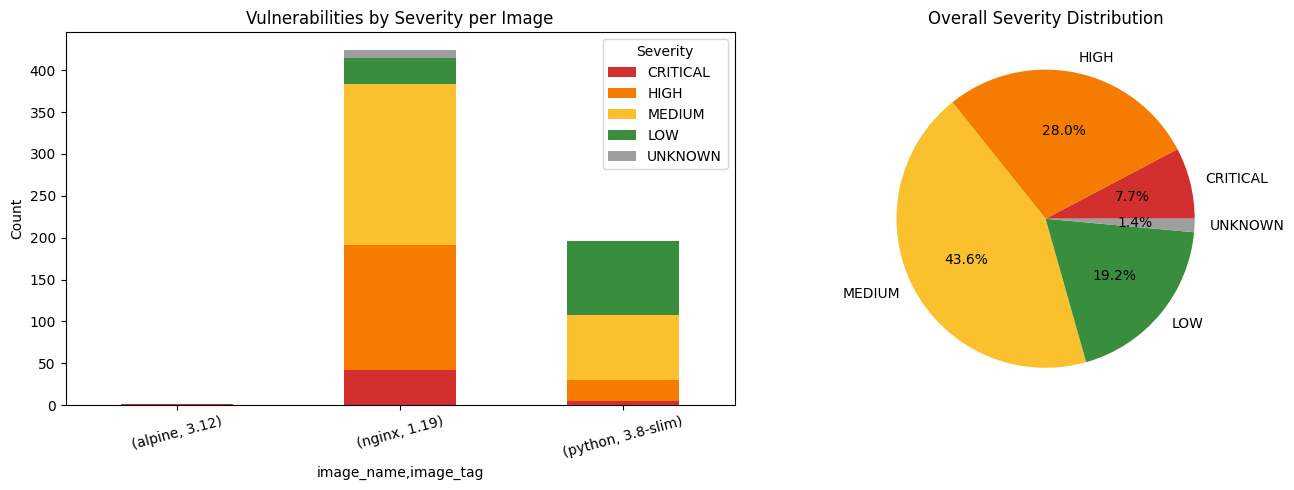

In [8]:
# --- Visualize severity distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stacked bar chart per image
colors = {'CRITICAL': '#d32f2f', 'HIGH': '#f57c00', 'MEDIUM': '#fbc02d', 'LOW': '#388e3c', 'UNKNOWN': '#9e9e9e'}
severity_pivot.plot(
    kind='bar', stacked=True, ax=axes[0],
    color=[colors.get(c, '#ccc') for c in severity_pivot.columns]
)
axes[0].set_title('Vulnerabilities by Severity per Image')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(title='Severity')

# Overall severity pie chart
sev_counts = df['severity'].value_counts()
sev_counts = sev_counts.reindex([s for s in severity_order if s in sev_counts.index])
sev_counts.plot(
    kind='pie', ax=axes[1], autopct='%1.1f%%',
    colors=[colors.get(s, '#ccc') for s in sev_counts.index]
)
axes[1].set_title('Overall Severity Distribution')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [9]:
# --- CVEs that appear in MULTIPLE images (shared vulnerabilities) ---
print("CVEs FOUND IN MULTIPLE IMAGES")
print("=" * 60)
print("(This is what GET /api/cves/:cve_id/images is about)\n")

cve_image_count = df.groupby('cve_id')['image_name'].nunique().reset_index(name='image_count')
shared_cves = cve_image_count[cve_image_count['image_count'] > 1].sort_values('image_count', ascending=False)

if len(shared_cves) > 0:
    print(f"Found {len(shared_cves)} CVEs affecting multiple images:\n")
    for _, row in shared_cves.head(15).iterrows():
        cve = row['cve_id']
        affected = df[df['cve_id'] == cve][['image_name', 'image_tag', 'package_name', 'severity']].drop_duplicates()
        sev = affected['severity'].iloc[0]
        images = [f"{r.image_name}:{r.image_tag}" for _, r in affected.iterrows()]
        print(f"  {cve} [{sev:>8}] -> {', '.join(images)}")
else:
    print("No shared CVEs found across the 3 sample images.")
    print("(This is expected - alpine, nginx, and python use different base images/packages)")
    print("When you scan all 10 images, Debian-based ones will share many CVEs.")

CVEs FOUND IN MULTIPLE IMAGES
(This is what GET /api/cves/:cve_id/images is about)

Found 9 CVEs affecting multiple images:

  CVE-2016-2781 [     LOW] -> nginx:1.19, python:3.8-slim
  CVE-2022-37434 [CRITICAL] -> nginx:1.19, alpine:3.12
  CVE-2023-29383 [     LOW] -> nginx:1.19, nginx:1.19, python:3.8-slim, python:3.8-slim
  CVE-2023-31484 [    HIGH] -> nginx:1.19, python:3.8-slim
  CVE-2023-45853 [CRITICAL] -> nginx:1.19, python:3.8-slim
  CVE-2023-4641 [  MEDIUM] -> nginx:1.19, nginx:1.19, python:3.8-slim, python:3.8-slim
  CVE-2023-50495 [  MEDIUM] -> nginx:1.19, nginx:1.19, nginx:1.19, nginx:1.19, python:3.8-slim, python:3.8-slim, python:3.8-slim, python:3.8-slim
  CVE-2023-52425 [    HIGH] -> nginx:1.19, python:3.8-slim
  CVE-2024-22365 [  MEDIUM] -> nginx:1.19, nginx:1.19, nginx:1.19, nginx:1.19, python:3.8-slim, python:3.8-slim, python:3.8-slim, python:3.8-slim


In [10]:
# --- Unique CVE IDs across all images ---
unique_cves = df['cve_id'].nunique()
total_rows = len(df)
print(f"Total vulnerability rows : {total_rows}")
print(f"Unique CVE IDs          : {unique_cves}")
print(f"Duplicates (same CVE,   : {total_rows - unique_cves}")
print(f"  diff image/package)")
print()
print("This is WHY you need a many-to-many relationship:")
print("  - 1 CVE can affect many images (shared base packages)")
print("  - 1 image has many CVEs")
print("  - The SAME CVE in different images may have different installed/fixed versions")

Total vulnerability rows : 621
Unique CVE IDs          : 378
Duplicates (same CVE,   : 243
  diff image/package)

This is WHY you need a many-to-many relationship:
  - 1 CVE can affect many images (shared base packages)
  - 1 image has many CVEs
  - The SAME CVE in different images may have different installed/fixed versions


In [11]:
# --- Package class breakdown ---
print("PACKAGE CLASS BREAKDOWN")
print("=" * 50)
print(df.groupby(['image_name', 'pkg_class', 'pkg_type']).size().reset_index(name='vuln_count').to_string(index=False))
print()
print("os-pkgs  = System packages (apt/apk installed)")
print("lang-pkgs = Language packages (pip/npm/go dependencies)")

PACKAGE CLASS BREAKDOWN
image_name pkg_class   pkg_type  vuln_count
    alpine   os-pkgs     alpine           1
     nginx   os-pkgs     debian         424
    python lang-pkgs python-pkg           7
    python   os-pkgs     debian         189

os-pkgs  = System packages (apt/apk installed)
lang-pkgs = Language packages (pip/npm/go dependencies)


In [12]:
# --- Fix availability ---
print("FIX AVAILABILITY")
print("=" * 50)
fix_counts = df['fix_status'].value_counts()
print(fix_counts)
print()
has_fix = df['fixed_version'].notna().sum()
no_fix = df['fixed_version'].isna().sum()
print(f"Has fixed_version: {has_fix} ({has_fix/len(df)*100:.1f}%)")
print(f"No fix available : {no_fix} ({no_fix/len(df)*100:.1f}%)")
print()
print("Tip: 'fixed' + 'affected' are the most common statuses.")
print("'fixed' means an upgrade is available. 'affected' means no patch yet.")

FIX AVAILABILITY
fix_status
fixed           423
affected        147
will_not_fix     39
fix_deferred     12
Name: count, dtype: int64

Has fixed_version: 423 (68.1%)
No fix available : 198 (31.9%)

Tip: 'fixed' + 'affected' are the most common statuses.
'fixed' means an upgrade is available. 'affected' means no patch yet.


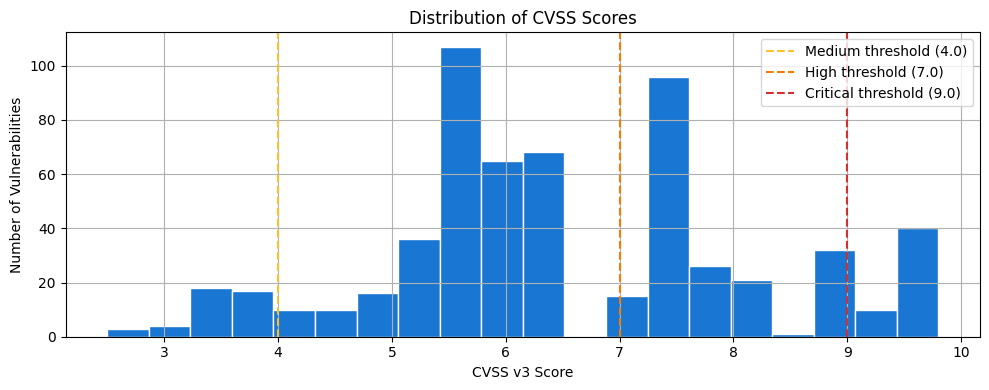


CVSS Score Stats: min=2.5, max=9.8, mean=6.5, median=6.5


In [13]:
# --- CVSS score distribution ---
cvss_scores = df['cvss_score'].dropna()
if len(cvss_scores) > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    cvss_scores.hist(bins=20, ax=ax, color='#1976d2', edgecolor='white')
    ax.set_xlabel('CVSS v3 Score')
    ax.set_ylabel('Number of Vulnerabilities')
    ax.set_title('Distribution of CVSS Scores')
    
    # Add severity band markers
    ax.axvline(x=4.0, color='#fbc02d', linestyle='--', label='Medium threshold (4.0)')
    ax.axvline(x=7.0, color='#f57c00', linestyle='--', label='High threshold (7.0)')
    ax.axvline(x=9.0, color='#d32f2f', linestyle='--', label='Critical threshold (9.0)')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    print(f"\nCVSS Score Stats: min={cvss_scores.min()}, max={cvss_scores.max()}, "
          f"mean={cvss_scores.mean():.1f}, median={cvss_scores.median():.1f}")
else:
    print("No CVSS scores available in the data.")

## 8. Database Schema Design

Now that you see the data shape, here's how to model it:

```
images              image_cves (junction)       cves
+-----------+       +-------------------+       +-----------+
| id (PK)   |<----->| image_id (FK)     |<----->| id (PK)   |
| name      |       | cve_id (FK)       |       | cve_id    |
| tag       |       | package_name      |       | severity  |
| os_family |       | installed_version |       | cvss_score|
| os_version|       | fixed_version     |       | title     |
| scan_status|      | fix_status        |       | description|
| scanned_at|       | pkg_class         |       | published |
+-----------+       +-------------------+       +-----------+
```

### Why this design?

1. **`images`** - One row per unique image (e.g., `nginx:1.19`). Stores scan metadata.
2. **`cves`** - One row per unique CVE ID. Severity/score are properties of the CVE itself.
3. **`image_cves`** (junction table) - Links images to CVEs. Stores the **relationship-specific** data:
   - `package_name` - which package in THIS image is affected
   - `installed_version` - what version THIS image has
   - `fixed_version` - what version would fix it in THIS image's OS

### Why not just one flat table?
- CVE severity would be duplicated hundreds of times
- Updating a CVE's info would require changing many rows
- Querying "all images affected by CVE-X" would be slow

In [14]:
# Let's simulate what each table would look like

# --- IMAGES table ---
images_table = df.groupby(['image_name', 'image_tag', 'os_family', 'os_version']).agg(
    total_cves=('cve_id', 'count'),
    unique_cves=('cve_id', 'nunique'),
).reset_index()

print("IMAGES TABLE (what you'd store)")
print("=" * 60)
print(images_table.to_string(index=False))

IMAGES TABLE (what you'd store)
image_name image_tag os_family os_version  total_cves  unique_cves
    alpine      3.12    alpine    3.12.12           1            1
     nginx      1.19    debian       10.9         424          279
    python  3.8-slim    debian       12.7         196          107


In [15]:
# --- CVES table (deduplicated) ---
cves_table = df.drop_duplicates(subset='cve_id')[['cve_id', 'severity', 'cvss_score', 'title']].sort_values('cve_id')

print("CVES TABLE (deduplicated, unique CVEs)")
print("=" * 60)
print(f"Total unique CVEs: {len(cves_table)}")
print()
print(cves_table.head(15).to_string(index=False))
print("...")

CVES TABLE (deduplicated, unique CVEs)
Total unique CVEs: 378

        cve_id severity  cvss_score                                                                                                     title
 CVE-2005-2541      LOW         7.0                               tar: does not properly warn the user when extracting setuid or setgid files
 CVE-2007-5686      LOW         NaN                                initscripts in rPath Linux 1 sets insecure permissions for the /var/lo ...
 CVE-2010-4756      LOW         NaN glibc: glob implementation can cause excessive CPU and memory consumption due to crafted glob expressions
 CVE-2011-3374      LOW         3.7                                It was found that apt-key in apt, all versions, do not correctly valid ...
 CVE-2011-3389      LOW         NaN                                         HTTPS: block-wise chosen-plaintext attack against SSL/TLS (BEAST)
 CVE-2011-4116      LOW         3.3                                                  

In [16]:
# --- IMAGE_CVES junction table ---
junction_table = df[['image_name', 'image_tag', 'cve_id', 'package_name', 
                      'installed_version', 'fixed_version', 'fix_status', 'pkg_class']]

print("IMAGE_CVES JUNCTION TABLE (relationship data)")
print("=" * 60)
print(f"Total rows: {len(junction_table)} (one per image-cve-package combination)")
print()
print(junction_table.head(10).to_string(index=False))
print("...")

IMAGE_CVES JUNCTION TABLE (relationship data)
Total rows: 621 (one per image-cve-package combination)

image_name image_tag         cve_id package_name installed_version      fixed_version   fix_status pkg_class
     nginx      1.19 CVE-2021-37600     bsdutils      1:2.33.1-0.1 2.33.1-0.1+deb10u1        fixed   os-pkgs
     nginx      1.19 CVE-2024-28085     bsdutils      1:2.33.1-0.1 2.33.1-0.1+deb10u1        fixed   os-pkgs
     nginx      1.19  CVE-2016-2781    coreutils            8.30-3                NaN will_not_fix   os-pkgs
     nginx      1.19 CVE-2022-32221         curl  7.64.0-4+deb10u2   7.64.0-4+deb10u4        fixed   os-pkgs
     nginx      1.19 CVE-2021-22946         curl  7.64.0-4+deb10u2   7.64.0-4+deb10u3        fixed   os-pkgs
     nginx      1.19 CVE-2022-22576         curl  7.64.0-4+deb10u2   7.64.0-4+deb10u3        fixed   os-pkgs
     nginx      1.19 CVE-2022-27781         curl  7.64.0-4+deb10u2   7.64.0-4+deb10u3        fixed   os-pkgs
     nginx      1.19 CVE-

## 9. API Response Simulation

Let's simulate what each API endpoint should return.

In [17]:
# --- GET /api/images ---
# List all scanned images with summary statistics

api_images = []
for (name, tag), group in df.groupby(['image_name', 'image_tag']):
    sev_counts = group['severity'].value_counts().to_dict()
    api_images.append({
        'name': name,
        'tag': tag,
        'os': f"{group['os_family'].iloc[0]} {group['os_version'].iloc[0]}",
        'scan_status': 'scanned',
        'total_cves': len(group),
        'severity_summary': {
            'CRITICAL': sev_counts.get('CRITICAL', 0),
            'HIGH': sev_counts.get('HIGH', 0),
            'MEDIUM': sev_counts.get('MEDIUM', 0),
            'LOW': sev_counts.get('LOW', 0),
        }
    })

print("GET /api/images")
print("=" * 60)
print(json.dumps(api_images, indent=2))

GET /api/images
[
  {
    "name": "alpine",
    "tag": "3.12",
    "os": "alpine 3.12.12",
    "scan_status": "scanned",
    "total_cves": 1,
    "severity_summary": {
      "CRITICAL": 1,
      "HIGH": 0,
      "MEDIUM": 0,
      "LOW": 0
    }
  },
  {
    "name": "nginx",
    "tag": "1.19",
    "os": "debian 10.9",
    "scan_status": "scanned",
    "total_cves": 424,
    "severity_summary": {
      "CRITICAL": 42,
      "HIGH": 149,
      "MEDIUM": 193,
      "LOW": 31
    }
  },
  {
    "name": "python",
    "tag": "3.8-slim",
    "os": "debian 12.7",
    "scan_status": "scanned",
    "total_cves": 196,
    "severity_summary": {
      "CRITICAL": 5,
      "HIGH": 25,
      "MEDIUM": 78,
      "LOW": 88
    }
  }
]


In [18]:
# --- GET /api/images/nginx/1.19/cves?severity=CRITICAL ---
# Returns all CVEs for an image, filtered by severity

image_name, image_tag, severity_filter = 'nginx', '1.19', 'CRITICAL'

filtered = df[
    (df['image_name'] == image_name) & 
    (df['image_tag'] == image_tag) &
    (df['severity'] == severity_filter)
]

api_response = {
    'image': f"{image_name}:{image_tag}",
    'severity_filter': severity_filter,
    'total': len(filtered),
    'cves': [
        {
            'cve_id': row['cve_id'],
            'severity': row['severity'],
            'cvss_score': row['cvss_score'],
            'package_name': row['package_name'],
            'installed_version': row['installed_version'],
            'fixed_version': row['fixed_version'],
            'title': row['title'],
        }
        for _, row in filtered.head(5).iterrows()  # Show first 5
    ]
}

print(f"GET /api/images/{image_name}/{image_tag}/cves?severity={severity_filter}")
print("=" * 60)
print(json.dumps(api_response, indent=2, default=str))

GET /api/images/nginx/1.19/cves?severity=CRITICAL
{
  "image": "nginx:1.19",
  "severity_filter": "CRITICAL",
  "total": 42,
  "cves": [
    {
      "cve_id": "CVE-2022-32221",
      "severity": "CRITICAL",
      "cvss_score": 9.8,
      "package_name": "curl",
      "installed_version": "7.64.0-4+deb10u2",
      "fixed_version": "7.64.0-4+deb10u4",
      "title": "curl: POST following PUT confusion"
    },
    {
      "cve_id": "CVE-2022-1664",
      "severity": "CRITICAL",
      "cvss_score": 9.8,
      "package_name": "dpkg",
      "installed_version": "1.19.7",
      "fixed_version": "1.19.8",
      "title": "Dpkg::Source::Archive in dpkg, the Debian package management system, b ..."
    },
    {
      "cve_id": "CVE-2021-33574",
      "severity": "CRITICAL",
      "cvss_score": 9.8,
      "package_name": "libc-bin",
      "installed_version": "2.28-10",
      "fixed_version": "2.28-10+deb10u2",
      "title": "glibc: mq_notify does not handle separately allocated thread attributes

In [19]:
# --- GET /api/cves/:cve_id/images ---
# Returns all images affected by a specific CVE

# Pick a CVE that exists in our data
sample_cve = df['cve_id'].value_counts().index[0]  # Most common CVE
cve_data = df[df['cve_id'] == sample_cve]

api_response_cve = {
    'cve_id': sample_cve,
    'severity': cve_data['severity'].iloc[0],
    'title': cve_data['title'].iloc[0],
    'affected_images': [
        {
            'image': f"{row['image_name']}:{row['image_tag']}",
            'package_name': row['package_name'],
            'installed_version': row['installed_version'],
            'fixed_version': row['fixed_version'],
        }
        for _, row in cve_data.iterrows()
    ]
}

print(f"GET /api/cves/{sample_cve}/images")
print("=" * 60)
print(json.dumps(api_response_cve, indent=2, default=str))

GET /api/cves/CVE-2021-37600/images
{
  "cve_id": "CVE-2021-37600",
  "severity": "MEDIUM",
  "title": "util-linux: integer overflow can lead to buffer overflow in get_sem_elements() in sys-utils/ipcutils.c",
  "affected_images": [
    {
      "image": "nginx:1.19",
      "package_name": "bsdutils",
      "installed_version": "1:2.33.1-0.1",
      "fixed_version": "2.33.1-0.1+deb10u1"
    },
    {
      "image": "nginx:1.19",
      "package_name": "fdisk",
      "installed_version": "2.33.1-0.1",
      "fixed_version": "2.33.1-0.1+deb10u1"
    },
    {
      "image": "nginx:1.19",
      "package_name": "libblkid1",
      "installed_version": "2.33.1-0.1",
      "fixed_version": "2.33.1-0.1+deb10u1"
    },
    {
      "image": "nginx:1.19",
      "package_name": "libfdisk1",
      "installed_version": "2.33.1-0.1",
      "fixed_version": "2.33.1-0.1+deb10u1"
    },
    {
      "image": "nginx:1.19",
      "package_name": "libmount1",
      "installed_version": "2.33.1-0.1",
      "fixed

## 10. Design Patterns & Architecture Terms

### Terms you should know for this assignment:

| Pattern/Term | What It Means | Where It Applies |
|---|---|---|
| **Composition Root** | Single place where all dependencies are wired together | `app/core/container.py` |
| **Dependency Injection** | Pass dependencies to constructors instead of creating them inside | Services receive DB session, scanner client, etc. |
| **Junction/Bridge Table** | Table that links two entities in a many-to-many relationship | `image_cves` table |
| **Background Worker** | Process that runs tasks outside the request-response cycle | Trivy scan runs in background, not during API request |
| **Periodic Scheduler** | Triggers tasks at regular intervals | APScheduler running scans every 15 minutes |
| **Idempotent** | Running the same operation twice produces the same result | Re-scanning replaces old results, doesn't duplicate |
| **Graceful Error Handling** | Handle failures without crashing | Trivy fails on one image? Log it, continue with others |
| **Health Check** | Endpoint that reports service status | `GET /health` returns DB connectivity, scanner status |
| **Thin Controller** | Route handler only validates + delegates to service layer | No business logic in route functions |
| **Repository Pattern** | Abstraction over database queries | Service calls `repo.get_cves_for_image()` not raw SQL |
| **DTO (Data Transfer Object)** | Object shaped for API input/output (Pydantic models) | `ImageResponse`, `CVEListResponse` schemas |
| **KISS** | Keep It Simple, Stupid | Don't over-engineer for 10 images |
| **YAGNI** | You Aren't Gonna Need It | No pagination if not required, no auth if not asked |

## 11. Architecture Overview

Based on the CLAUDE.md preferences, the project structure will look like:

```
app/
├── api/
│   ├── routes/
│   │   ├── images.py          # GET /api/images, GET /api/images/:name/:tag/cves
│   │   ├── cves.py            # GET /api/cves, GET /api/cves/:cve_id/images
│   │   └── health.py          # GET /health
│   ├── dependencies.py        # FastAPI Depends (get_db, get_scanner)
│   └── exception_handlers.py
├── core/
│   ├── settings.py            # Pydantic-settings (scan interval, DB URL, etc.)
│   ├── container.py           # Composition root (wire everything)
│   ├── exceptions.py
│   └── clients/
│       ├── database.py        # SQLModel engine + session
│       └── trivy.py           # Trivy subprocess wrapper
├── models/
│   ├── image.py               # SQLModel: Image table
│   ├── cve.py                 # SQLModel: CVE table  
│   └── image_cve.py           # SQLModel: junction table
├── schemas/
│   ├── image.py               # Pydantic: API request/response schemas
│   └── cve.py
├── services/
│   ├── scanner.py             # Trivy scan logic + result parsing
│   ├── image_service.py       # Image CRUD + queries
│   └── cve_service.py         # CVE queries
└── scheduler.py               # APScheduler: periodic scan job

docker-compose.yml             # DB + app services
requirements.txt
```

### Data flow:
```
Scheduler (every 15 min)
    │
    ▼
scanner.py  ──> trivy.py (subprocess: trivy image --format json)
    │                         │
    │                         ▼
    │                    Parse JSON output
    │                         │
    ▼                         ▼
image_service.py  <──  Flattened vuln data
    │
    ▼
database.py  ──>  SQLModel tables (images, cves, image_cves)
    │
    ▼
API routes  ──>  JSON responses to client
```

## 12. Quick Reference: The 10 Images You'll Scan

| Image | Base OS | Expected Vuln Count | Notes |
|-------|---------|-------------------|-------|
| `nginx:1.19` | Debian 10 (Buster) | Very High (~400+) | Old Debian, lots of vulns |
| `postgres:12` | Debian | High | DB server + system libs |
| `redis:6.0` | Debian | High | Similar Debian base |
| `node:14-alpine` | Alpine | Low-Medium | Alpine = minimal base |
| `python:3.8-slim` | Debian 12 | High (~200) | OS pkgs + Python pkgs |
| `alpine:3.12` | Alpine | Very Low (~1) | Minimal, few packages |
| `ubuntu:20.04` | Ubuntu | Medium | Older Ubuntu LTS |
| `mysql:8.0` | Oracle Linux | Medium | Different OS advisory source |
| `mongo:4.4` | Ubuntu/Debian | High | Large image, many deps |
| `httpd:2.4` | Debian | High | Apache on Debian |

**Expect total CVEs in the range of 1,000-3,000+ across all images, with significant overlap for Debian-based images.**

In [20]:
# --- Summary stats for your data ---
print("DATA SUMMARY (3 sample images)")
print("=" * 50)
print(f"Images scanned        : {df[['image_name','image_tag']].drop_duplicates().shape[0]}")
print(f"Total vuln rows       : {len(df)}")
print(f"Unique CVE IDs        : {df['cve_id'].nunique()}")
print(f"Unique packages       : {df['package_name'].nunique()}")
print(f"Severities found      : {sorted(df['severity'].unique())}")
print(f"Package classes       : {sorted(df['pkg_class'].unique())}")
print(f"Fix statuses          : {sorted(df['fix_status'].dropna().unique())}")
print()
print("You now understand the data. Ready to build!")

DATA SUMMARY (3 sample images)
Images scanned        : 3
Total vuln rows       : 621
Unique CVE IDs        : 378
Unique packages       : 94
Severities found      : ['CRITICAL', 'HIGH', 'LOW', 'MEDIUM', 'UNKNOWN']
Package classes       : ['lang-pkgs', 'os-pkgs']
Fix statuses          : ['affected', 'fix_deferred', 'fixed', 'will_not_fix']

You now understand the data. Ready to build!


## 13. Domain Pydantic Models for Trivy Output

We do **not** model Trivy's full nested JSON schema -- that would be tight coupling to an external tool's internals. Instead, we define slim **domain models** that capture only the fields we extract. The `TrivyClient` is the only place that knows Trivy's JSON structure and translates it into these models.

In [ ]:
from pydantic import BaseModel


class VulnerabilityDetail(BaseModel):
    """A single vulnerability extracted from a Trivy scan result."""
    cve_id: str
    severity: str
    package_name: str
    installed_version: str
    fixed_version: str | None = None
    description: str | None = None


class ScanResult(BaseModel):
    """Parsed output of a Trivy image scan -- our domain model, not Trivy's schema."""
    image_name: str
    image_tag: str
    vulnerabilities: list[VulnerabilityDetail]


# --- Prove it works with real data from the notebook ---

def parse_trivy_output(raw: dict) -> ScanResult:
    """Translate raw Trivy JSON into our domain model. This logic lives in TrivyClient."""
    artifact = raw["ArtifactName"]
    parts = artifact.rsplit(":", 1)
    name = parts[0]
    tag = parts[1] if len(parts) > 1 else "latest"

    vulns = []
    for result in raw.get("Results") or []:
        for v in result.get("Vulnerabilities") or []:
            vulns.append(VulnerabilityDetail(
                cve_id=v["VulnerabilityID"],
                severity=v.get("Severity", "UNKNOWN"),
                package_name=v["PkgName"],
                installed_version=v["InstalledVersion"],
                fixed_version=v.get("FixedVersion"),
                description=v.get("Title"),
            ))

    return ScanResult(image_name=name, image_tag=tag, vulnerabilities=vulns)


# Parse all 3 sample scans
for name, raw_data in scans.items():
    result = parse_trivy_output(raw_data)
    print(f"{result.image_name}:{result.image_tag} -> {len(result.vulnerabilities)} vulns")

# Show one entry as proof
sample = parse_trivy_output(scans["nginx"])
print(f"\nSample vulnerability (Pydantic model):")
print(sample.vulnerabilities[0].model_dump_json(indent=2))